In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data_processed/metro_trips_clean.csv", parse_dates=['date'])
df.head()

,metro_station,month,trips,year,load_timestamp,month_num,date,line,latitude,longitude
0,ADCB Metro Station,Jan,576653,2018,2018-03-07T15:45:02.000Z,1,2018-01-01,Red,25.24451,55.298183
1,ADCB Metro Station,Feb,537043,2018,2018-04-02T20:58:20.000Z,2,2018-02-01,Red,25.24451,55.298183
2,ADCB Metro Station,Mar,589172,2018,2018-04-30T20:08:02.000Z,3,2018-03-01,Red,25.24451,55.298183
3,ADCB Metro Station,Apr,558949,2018,2018-06-04T22:45:38.000Z,4,2018-04-01,Red,25.24451,55.298183
4,ADCB Metro Station,May,557432,2018,2018-10-11T11:46:58.000Z,5,2018-05-01,Red,25.24451,55.298183


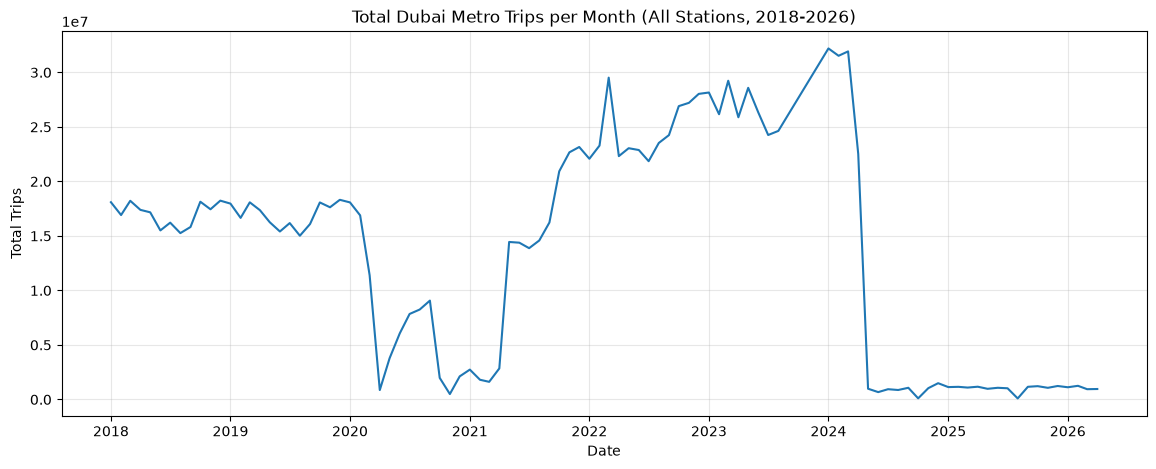

In [2]:
system_total = df.groupby('date')['trips'].sum()

plt.figure(figsize=(14,5))
plt.plot(system_total.index, system_total.values)
plt.title("Total Dubai Metro Trips per Month (All Stations, 2018-2026)")
plt.xlabel("Date")
plt.ylabel("Total Trips")
plt.grid(alpha=0.3)
plt.savefig("../docs/eda_01_system_total.png", dpi=150, bbox_inches='tight')
plt.show()

In [3]:
recent = df[df['date'] >= '2024-01-01']
stations_per_month = recent.groupby('date')['metro_station'].nunique()
print(stations_per_month)

date
2024-01-01    53
2024-02-01    53
2024-03-01    53
2024-04-01    53
2024-05-01    53
2024-06-01    53
2024-07-01    53
2024-08-01    53
2024-09-01    53
2024-10-01    53
2024-11-01    53
2024-12-01    53
2025-01-01    53
2025-02-01    53
2025-03-01    53
2025-04-01    53
2025-05-01    53
2025-06-01    53
2025-07-01    53
2025-08-01    53
2025-09-01    53
2025-10-01    53
2025-11-01    53
2025-12-01    53
2026-01-01    53
2026-02-01    53
2026-03-01    53
2026-04-01    53
Name: metro_station, dtype: int64


In [4]:
sample_station = df[df['metro_station'] == 'ADCB Metro Station'].sort_values('date')
print(sample_station[['date','trips']].tail(30))

         date    trips
66 2023-07-01   809219
67 2023-08-01   823153
68 2024-01-01  1025278
69 2024-02-01   991210
70 2024-03-01  1040341
71 2024-04-01   757460
72 2024-05-01    29217
73 2024-06-01    25791
74 2024-07-01    28066
75 2024-08-01    32198
76 2024-09-01    30275
77 2024-10-01     2019
78 2024-11-01    36763
79 2024-12-01    58829
80 2025-01-01    33980
81 2025-02-01    34520
82 2025-03-01    41998
83 2025-04-01    34105
84 2025-05-01    34338
85 2025-06-01    32427
86 2025-07-01    31219
87 2025-08-01     1942
88 2025-09-01    33587
89 2025-10-01    36384
90 2025-11-01    44579
91 2025-12-01    37531
92 2026-01-01    38508
93 2026-02-01    39966
94 2026-03-01    29480
95 2026-04-01    29938


In [5]:
# Check the ratio between last pre-drop value and first post-drop value, per station
before = df[df['date']=='2024-04-01'].set_index('metro_station')['trips']
after = df[df['date']=='2024-05-01'].set_index('metro_station')['trips']

ratio = (before / after).dropna()
print(ratio.describe())
print("\nMedian ratio:", ratio.median())

count    53.000000
mean     23.508069
std       4.933443
min      12.171795
25%      21.860501
50%      23.147118
75%      24.719737
max      44.733618
Name: trips, dtype: float64

Median ratio: 23.147118394402504


In [6]:
import calendar

# For each month from 2024-05 onward, check trips value against days/weekdays in that month
post_period = df[df['date'] >= '2024-05-01'].copy()

def days_in_month(d):
    return calendar.monthrange(d.year, d.month)[1]

def weekdays_in_month(d, weekday_start=6, weekday_end=3):
    # Dubai work week: Sunday(6)-Thursday(3) in Python's weekday() where Mon=0..Sun=6
    import numpy as np
    days = pd.date_range(d, periods=days_in_month(d), freq='D')
    return sum(1 for day in days if day.weekday() in [6,0,1,2,3])  # Sun,Mon,Tue,Wed,Thu

post_period['days_in_month'] = post_period['date'].apply(days_in_month)
post_period['weekdays_in_month'] = post_period['date'].apply(weekdays_in_month)

# Take one station, check correlation between trips and weekdays in month
adcb_post = post_period[post_period['metro_station']=='ADCB Metro Station']
print(adcb_post[['date','trips','days_in_month','weekdays_in_month']])

         date  trips  days_in_month  weekdays_in_month
72 2024-05-01  29217             31                 22
73 2024-06-01  25791             30                 21
74 2024-07-01  28066             31                 23
75 2024-08-01  32198             31                 21
76 2024-09-01  30275             30                 22
77 2024-10-01   2019             31                 23
78 2024-11-01  36763             30                 20
79 2024-12-01  58829             31                 23
80 2025-01-01  33980             31                 22
81 2025-02-01  34520             28                 20
82 2025-03-01  41998             31                 22
83 2025-04-01  34105             30                 22
84 2025-05-01  34338             31                 21
85 2025-06-01  32427             30                 22
86 2025-07-01  31219             31                 23
87 2025-08-01   1942             31                 21
88 2025-09-01  33587             30                 22
89 2025-10

In [7]:
oct24 = df[df['date']=='2024-10-01']['trips']
aug25 = df[df['date']=='2025-08-01']['trips']
normal_month = df[df['date']=='2025-01-01']['trips']

print("Oct 2024 - mean:", oct24.mean(), "median:", oct24.median())
print("Aug 2025 - mean:", aug25.mean(), "median:", aug25.median())
print("Jan 2025 (normal) - mean:", normal_month.mean(), "median:", normal_month.median())

Oct 2024 - mean: 1925.7735849056603 median: 1409.0
Aug 2025 - mean: 1759.188679245283 median: 1141.0
Jan 2025 (normal) - mean: 21408.622641509435 median: 18217.0


In [8]:
correlation = post_period.groupby('date').apply(lambda g: None)  # placeholder, real check below
merged_check = adcb_post.copy()
print("\nCorrelation between trips and weekdays_in_month:", merged_check['trips'].corr(merged_check['weekdays_in_month']))


Correlation between trips and weekdays_in_month: -0.06979650230733132


In [9]:
post = df[df['date'] >= '2024-01-01']
print("Unique load_timestamps in this period:", post['load_timestamp'].nunique())
print(post.groupby('load_timestamp')['date'].agg(['min','max','count']).sort_values('count', ascending=False).head(15))

Unique load_timestamps in this period: 28
                                min        max  count
load_timestamp                                       
2024-03-08T15:34:09.000Z 2024-01-01 2024-01-01     53
2024-04-01T19:54:08.000Z 2024-02-01 2024-02-01     53
2024-06-03T20:35:40.000Z 2024-03-01 2024-03-01     53
2024-06-03T20:36:22.000Z 2024-04-01 2024-04-01     53
2024-06-12T01:46:33.000Z 2024-05-01 2024-05-01     53
2024-07-03T19:07:54.000Z 2024-06-01 2024-06-01     53
2024-08-03T19:08:46.000Z 2024-07-01 2024-07-01     53
2024-09-03T19:07:34.000Z 2024-08-01 2024-08-01     53
2024-09-28T19:10:13.000Z 2024-09-01 2024-09-01     53
2024-11-03T19:09:32.000Z 2024-10-01 2024-10-01     53
2024-12-03T19:06:43.000Z 2024-11-01 2024-11-01     53
2025-01-03T22:50:55.000Z 2024-12-01 2024-12-01     53
2025-02-03T19:34:11.000Z 2025-01-01 2025-01-01     53
2025-03-04T21:36:38.000Z 2025-02-01 2025-02-01     53
2025-04-03T19:11:17.000Z 2025-03-01 2025-03-01     53


In [10]:
cutoff_date = '2024-05-01'
df_model = df[df['date'] < cutoff_date].copy()

print("Rows before cutoff:", len(df_model))
print("Date range:", df_model['date'].min(), "to", df_model['date'].max())
print("Stations:", df_model['metro_station'].nunique())

df_model.to_csv("../data_processed/metro_trips_model_ready.csv", index=False)
print("Saved model-ready dataset.")

Rows before cutoff: 3617
Date range: 2018-01-01 00:00:00 to 2024-04-01 00:00:00
Stations: 53
Saved model-ready dataset.


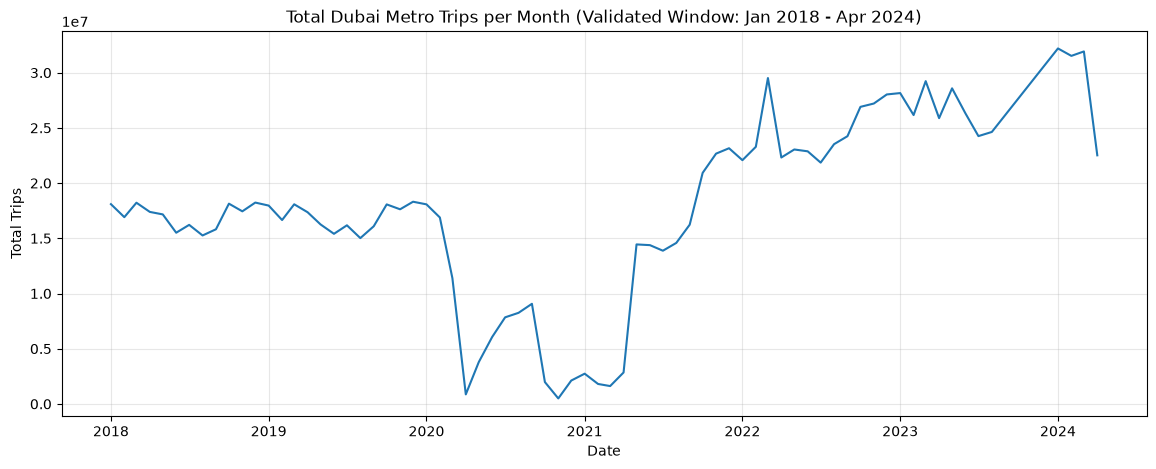

In [11]:
df_model = pd.read_csv("../data_processed/metro_trips_model_ready.csv", parse_dates=['date'])

system_total = df_model.groupby('date')['trips'].sum()

plt.figure(figsize=(14,5))
plt.plot(system_total.index, system_total.values)
plt.title("Total Dubai Metro Trips per Month (Validated Window: Jan 2018 - Apr 2024)")
plt.xlabel("Date")
plt.ylabel("Total Trips")
plt.grid(alpha=0.3)
plt.savefig("../docs/eda_02_system_total_validated.png", dpi=150, bbox_inches='tight')
plt.show()

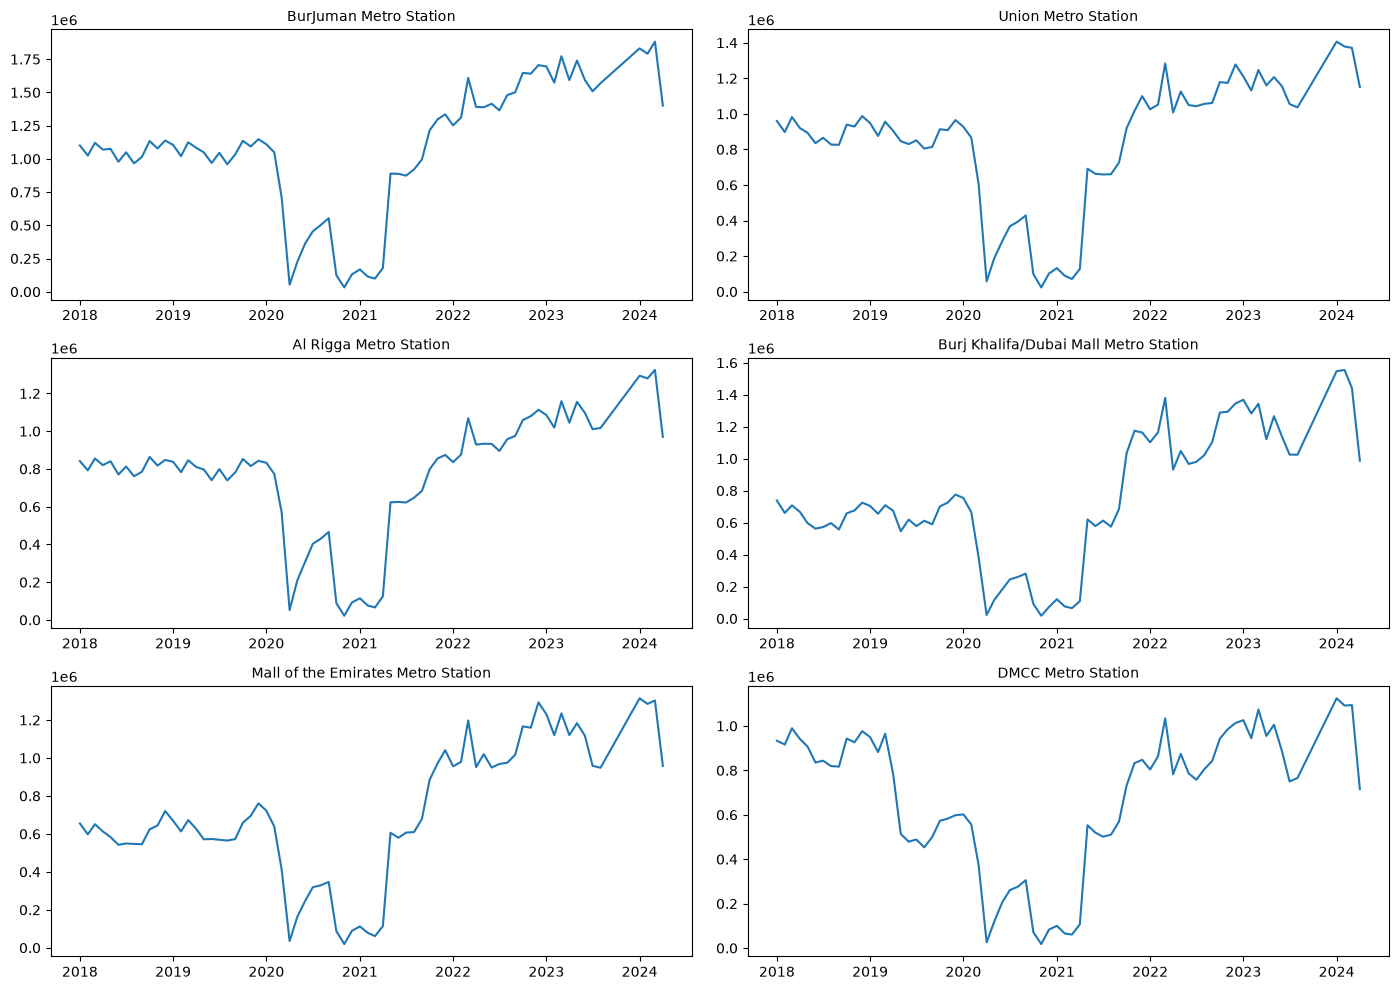

In [15]:
top_stations = df_model.groupby('metro_station')['trips'].sum().nlargest(6).index

fig, axes = plt.subplots(3, 2, figsize=(14, 10))
for ax, station in zip(axes.flat, top_stations):
    sub = df_model[df_model['metro_station'] == station]
    ax.plot(sub['date'], sub['trips'])
    ax.set_title(station, fontsize=10)
plt.tight_layout()
plt.savefig("../docs/eda_03_top_stations.png", dpi=150, bbox_inches='tight')
plt.show()

In [13]:
dmcc = df_model[df_model['metro_station'] == 'DMCC Metro Station']
print(dmcc[['date','trips']].to_string())

           date    trips
1485 2018-05-01   907594
1486 2018-06-01   835256
1487 2018-07-01   843477
1488 2018-08-01   819192
1489 2018-09-01   816907
1490 2018-10-01   943015
1491 2018-11-01   926537
1492 2018-12-01   976533
1493 2019-01-01   949838
1494 2019-02-01   882189
1495 2019-03-01   965485
1496 2019-04-01   784664
1497 2019-05-01   513682
1498 2019-06-01   479106
1499 2019-07-01   488622
1500 2019-08-01   453458
1501 2019-09-01   499710
1502 2019-10-01   572799
1503 2019-11-01   582765
1504 2019-12-01   598042
1505 2020-01-01   601447
1506 2020-02-01   556501
1507 2020-03-01   371107
1508 2020-04-01    25774
1509 2020-05-01   119341
1510 2020-06-01   205741
1511 2020-07-01   261032
1512 2020-08-01   276146
1513 2020-09-01   305521
1514 2020-10-01    71437
1515 2020-11-01    17828
1516 2020-12-01    82992
1517 2021-01-01   100105
1518 2021-02-01    65747
1519 2021-03-01    60758
1520 2021-04-01   107199
1521 2021-05-01   552955
1522 2021-06-01   519390
1523 2021-07-01   501329


In [14]:
df_model = df_model.sort_values(['metro_station', 'date']).reset_index(drop=True)

In [16]:
df_master = pd.read_csv("../data_processed/metro_trips_clean.csv", parse_dates=['date'])

# Check if it's sorted properly
is_sorted = df_master.groupby('metro_station')['date'].apply(lambda x: x.is_monotonic_increasing)
print("Stations NOT properly sorted:", is_sorted[~is_sorted].index.tolist())

Stations NOT properly sorted: ['DMCC Metro Station', 'Gold Souq Metro Station', 'Jabal Ali Metro Station', 'Mashreq Metro Station']


In [17]:
# Fix the master file
df_master = df_master.sort_values(['metro_station', 'date']).reset_index(drop=True)

# Verify the fix
is_sorted = df_master.groupby('metro_station')['date'].apply(lambda x: x.is_monotonic_increasing)
print("Stations NOT properly sorted after fix:", is_sorted[~is_sorted].index.tolist())

# Save corrected master file
df_master.to_csv("../data_processed/metro_trips_clean.csv", index=False)
print("Master file re-saved, sorted.")

# Regenerate model-ready file from the corrected master
cutoff_date = '2024-05-01'
df_model = df_master[df_master['date'] < cutoff_date].copy().reset_index(drop=True)
df_model.to_csv("../data_processed/metro_trips_model_ready.csv", index=False)
print("Model-ready file regenerated:", df_model.shape)

Stations NOT properly sorted after fix: []
Master file re-saved, sorted.
Model-ready file regenerated: (3617, 10)


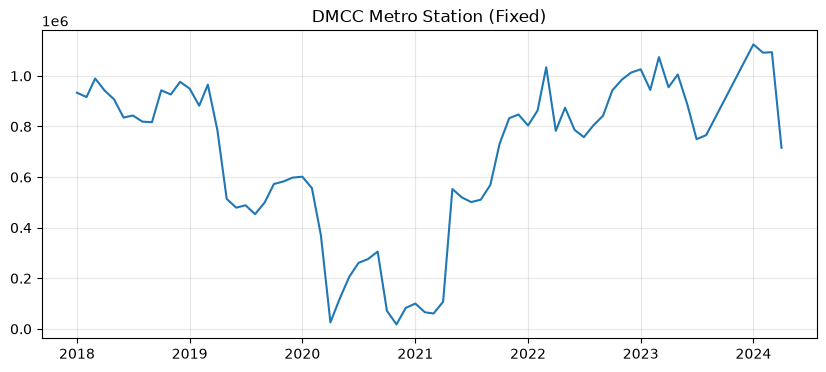

In [18]:
dmcc = df_model[df_model['metro_station'] == 'DMCC Metro Station']
plt.figure(figsize=(10,4))
plt.plot(dmcc['date'], dmcc['trips'])
plt.title("DMCC Metro Station (Fixed)")
plt.grid(alpha=0.3)
plt.show()

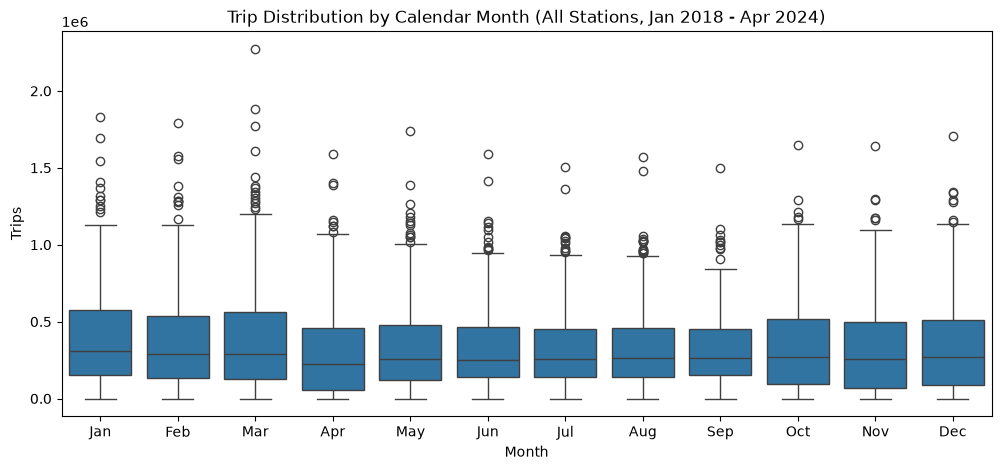

In [19]:
month_map = {'Jan':1,'Feb':2,'Mar':3,'Apr':4,'May':5,'Jun':6,
             'Jul':7,'Aug':8,'Sep':9,'Oct':10,'Nov':11,'Dec':12}

df_model['month_name'] = pd.Categorical(df_model['month'], categories=list(month_map.keys()), ordered=True)

plt.figure(figsize=(12,5))
sns.boxplot(data=df_model, x='month_name', y='trips')
plt.title("Trip Distribution by Calendar Month (All Stations, Jan 2018 - Apr 2024)")
plt.xlabel("Month")
plt.ylabel("Trips")
plt.savefig("../docs/eda_04_seasonal_boxplot.png", dpi=150, bbox_inches='tight')
plt.show()

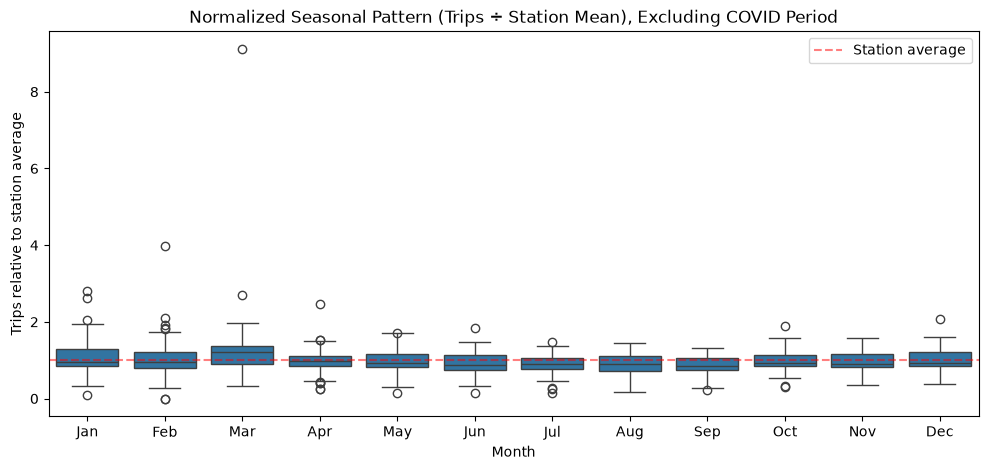

In [20]:
# Exclude 2020-2021 (COVID-distorted) and normalize each station's trips by its own mean
stable_period = df_model[(df_model['date'] < '2020-03-01') | (df_model['date'] >= '2022-01-01')].copy()

station_means = stable_period.groupby('metro_station')['trips'].transform('mean')
stable_period['trips_normalized'] = stable_period['trips'] / station_means

plt.figure(figsize=(12,5))
sns.boxplot(data=stable_period, x='month_name', y='trips_normalized')
plt.axhline(1.0, color='red', linestyle='--', alpha=0.5, label='Station average')
plt.title("Normalized Seasonal Pattern (Trips ÷ Station Mean), Excluding COVID Period")
plt.xlabel("Month")
plt.ylabel("Trips relative to station average")
plt.legend()
plt.savefig("../docs/eda_05_seasonal_normalized.png", dpi=150, bbox_inches='tight')
plt.show()

In [21]:
outlier = stable_period[stable_period['trips_normalized'] > 5]
print(outlier[['metro_station','date','trips','trips_normalized']])

           metro_station       date    trips  trips_normalized
2021  EXPO Metro Station 2022-03-01  2275405          9.126802


           date    trips
1999 2020-03-01        5
2000 2020-04-01        7
2001 2020-05-01       50
2002 2020-06-01       11
2003 2020-07-01        8
2004 2020-09-01       17
2005 2020-11-01        5
2006 2020-12-01      227
2007 2021-01-01      214
2008 2021-02-01      109
2009 2021-03-01      144
2010 2021-04-01      256
2011 2021-05-01     1425
2012 2021-06-01    11716
2013 2021-07-01    16501
2014 2021-08-01    29673
2015 2021-09-01   144962
2016 2021-10-01  1045401
2017 2021-11-01   835649
2018 2021-12-01   987169
2019 2022-01-01   700894
2020 2022-02-01   994374
2021 2022-03-01  2275405
2022 2022-04-01    64607
2023 2022-05-01    34209
2024 2022-06-01    35704
2025 2022-07-01    39296
2026 2022-08-01    43745
2027 2022-09-01    54799
2028 2022-10-01    83364
2029 2022-11-01   100177
2030 2022-12-01   187780
2031 2023-01-01   118683
2032 2023-02-01   101860
2033 2023-03-01   122235
2034 2023-04-01   114182
2035 2023-05-01   111334
2036 2023-06-01    91479
2037 2023-07-01    61673


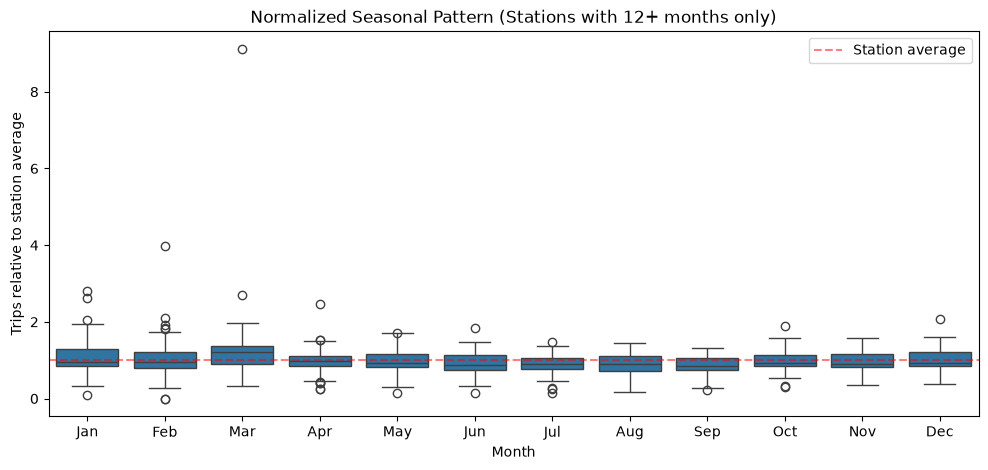

In [22]:
expo_history = df_model[df_model['metro_station']=='EXPO Metro Station'][['date','trips']]
print(expo_history)

# Only include stations with enough data (say 12+ months) in the stable period, for the seasonal chart
station_counts = stable_period.groupby('metro_station').size()
reliable_stations = station_counts[station_counts >= 12].index
stable_reliable = stable_period[stable_period['metro_station'].isin(reliable_stations)]

plt.figure(figsize=(12,5))
sns.boxplot(data=stable_reliable, x='month_name', y='trips_normalized')
plt.axhline(1.0, color='red', linestyle='--', alpha=0.5, label='Station average')
plt.title("Normalized Seasonal Pattern (Stations with 12+ months only)")
plt.xlabel("Month")
plt.ylabel("Trips relative to station average")
plt.legend()
plt.savefig("../docs/eda_06_seasonal_normalized_reliable.png", dpi=150, bbox_inches='tight')
plt.show()

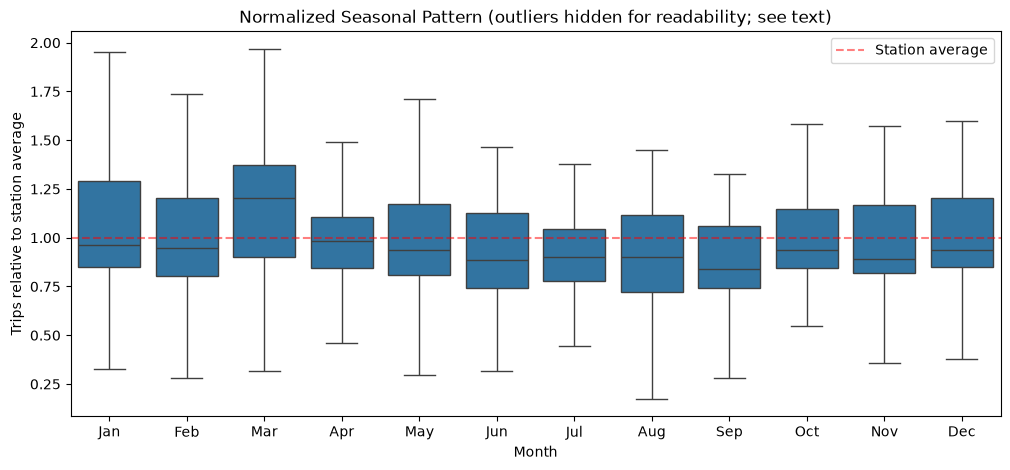

In [23]:
plt.figure(figsize=(12,5))
sns.boxplot(data=stable_reliable, x='month_name', y='trips_normalized', showfliers=False)
plt.axhline(1.0, color='red', linestyle='--', alpha=0.5, label='Station average')
plt.title("Normalized Seasonal Pattern (outliers hidden for readability; see text)")
plt.xlabel("Month")
plt.ylabel("Trips relative to station average")
plt.legend()
plt.savefig("../docs/eda_06_seasonal_normalized_final.png", dpi=150, bbox_inches='tight')
plt.show()

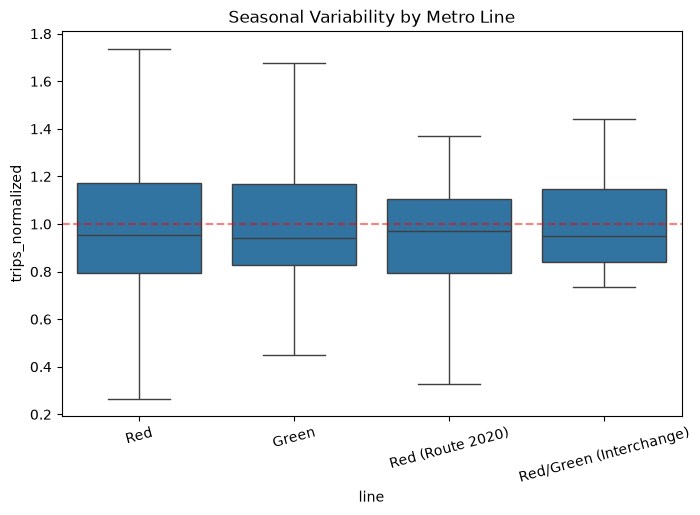

In [24]:
plt.figure(figsize=(8,5))
sns.boxplot(data=stable_reliable, x='line', y='trips_normalized', showfliers=False)
plt.axhline(1.0, color='red', linestyle='--', alpha=0.5)
plt.title("Seasonal Variability by Metro Line")
plt.xticks(rotation=15)
plt.savefig("../docs/eda_07_by_line.png", dpi=150, bbox_inches='tight')
plt.show()

In [25]:
df_model.to_csv("../data_processed/metro_trips_model_ready.csv", index=False)
print("Saved final EDA-validated dataset:", df_model.shape)

Saved final EDA-validated dataset: (3617, 11)


In [26]:
station_summary = df_model.groupby('metro_station').agg(
    line=('line', 'first'),
    n_months=('trips', 'count'),
    mean_trips=('trips', 'mean'),
    std_trips=('trips', 'std'),
    min_trips=('trips', 'min'),
    max_trips=('trips', 'max'),
    first_month=('date', 'min'),
    last_month=('date', 'max')
).round(0)

# Simple growth check: compare first available year's mean vs last available year's mean (excluding COVID 2020-2021)
def growth_pct(g):
    early = g[g['date'].dt.year.isin([2018,2019])]['trips'].mean()
    late = g[g['date'].dt.year.isin([2023,2024])]['trips'].mean()
    if pd.isna(early) or pd.isna(late) or early == 0:
        return None
    return round(((late - early) / early) * 100, 1)

growth = df_model.groupby('metro_station').apply(growth_pct)
station_summary['growth_2018_19_vs_2023_24_pct'] = growth

station_summary = station_summary.sort_values('mean_trips', ascending=False)
pd.set_option('display.max_rows', None)
print(station_summary)

station_summary.to_csv("../docs/station_summary_table.csv")
print("\nSaved full summary table.")

                                                          line  n_months  \
metro_station                                                              
BurJuman Metro Station                 Red/Green (Interchange)        72   
Union Metro Station                    Red/Green (Interchange)        72   
Al Rigga Metro Station                                     Red        72   
Burj Khalifa/Dubai Mall Metro Station                      Red        72   
Mall of the Emirates Metro Station                         Red        72   
DMCC Metro Station                                         Red        72   
Business Bay Metro Station                                 Red        72   
Deira City Centre Metro Station                            Red        72   
Al Fahidi Metro Station                                  Green        72   
Baniyas Square Metro Station                             Green        72   
ADCB Metro Station                                         Red        72   
Dubai Intern

C:\Users\user\AppData\Local\Temp\ipykernel_816\522257411.py:10: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).round(0)


In [27]:
# Stations with NaN growth (likely too few pre-2020 or post-2022 records to compare)
print("Stations with NaN growth:")
print(station_summary[station_summary['growth_2018_19_vs_2023_24_pct'].isna()].index.tolist())

# Stations with negative growth (declining ridership - worth understanding why)
print("\nStations with NEGATIVE growth:")
print(station_summary[station_summary['growth_2018_19_vs_2023_24_pct'] < 0][['mean_trips','growth_2018_19_vs_2023_24_pct']])

# Stations with unusually high volatility (std relative to mean)
station_summary['cv'] = (station_summary['std_trips'] / station_summary['mean_trips']).round(2)
print("\nTop 10 most volatile stations (coefficient of variation):")
print(station_summary.sort_values('cv', ascending=False)[['mean_trips','cv']].head(10))

# Stations with short data ranges
print("\nStations with fewer than 30 months of data:")
print(station_summary[station_summary['n_months'] < 30][['n_months','first_month','last_month']])

Stations with NaN growth:
['EXPO Metro Station', 'The Gardens Metro Station', 'Dubai Investment Park Metro Station', 'Discovery Gardens Metro Station', 'Al Furjan Metro Station', 'Jumeirah Golf Estates Metro Station']

Stations with NEGATIVE growth:
Empty DataFrame
Columns: [mean_trips, growth_2018_19_vs_2023_24_pct]
Index: []

Top 10 most volatile stations (coefficient of variation):
                                     mean_trips    cv
metro_station                                        
EXPO Metro Station                     205841.0  2.07
Jumeirah Golf Estates Metro Station     11788.0  1.00
Energy Metro Station                    17610.0  0.79
Jabal Ali Metro Station                 28648.0  0.77
Al Furjan Metro Station                 89348.0  0.73
Dubai Investment Park Metro Station    168208.0  0.69
Al Jadaf Metro Station                  87834.0  0.65
The Gardens Metro Station              194880.0  0.63
Discovery Gardens Metro Station         96286.0  0.62
Emirates Towers Me

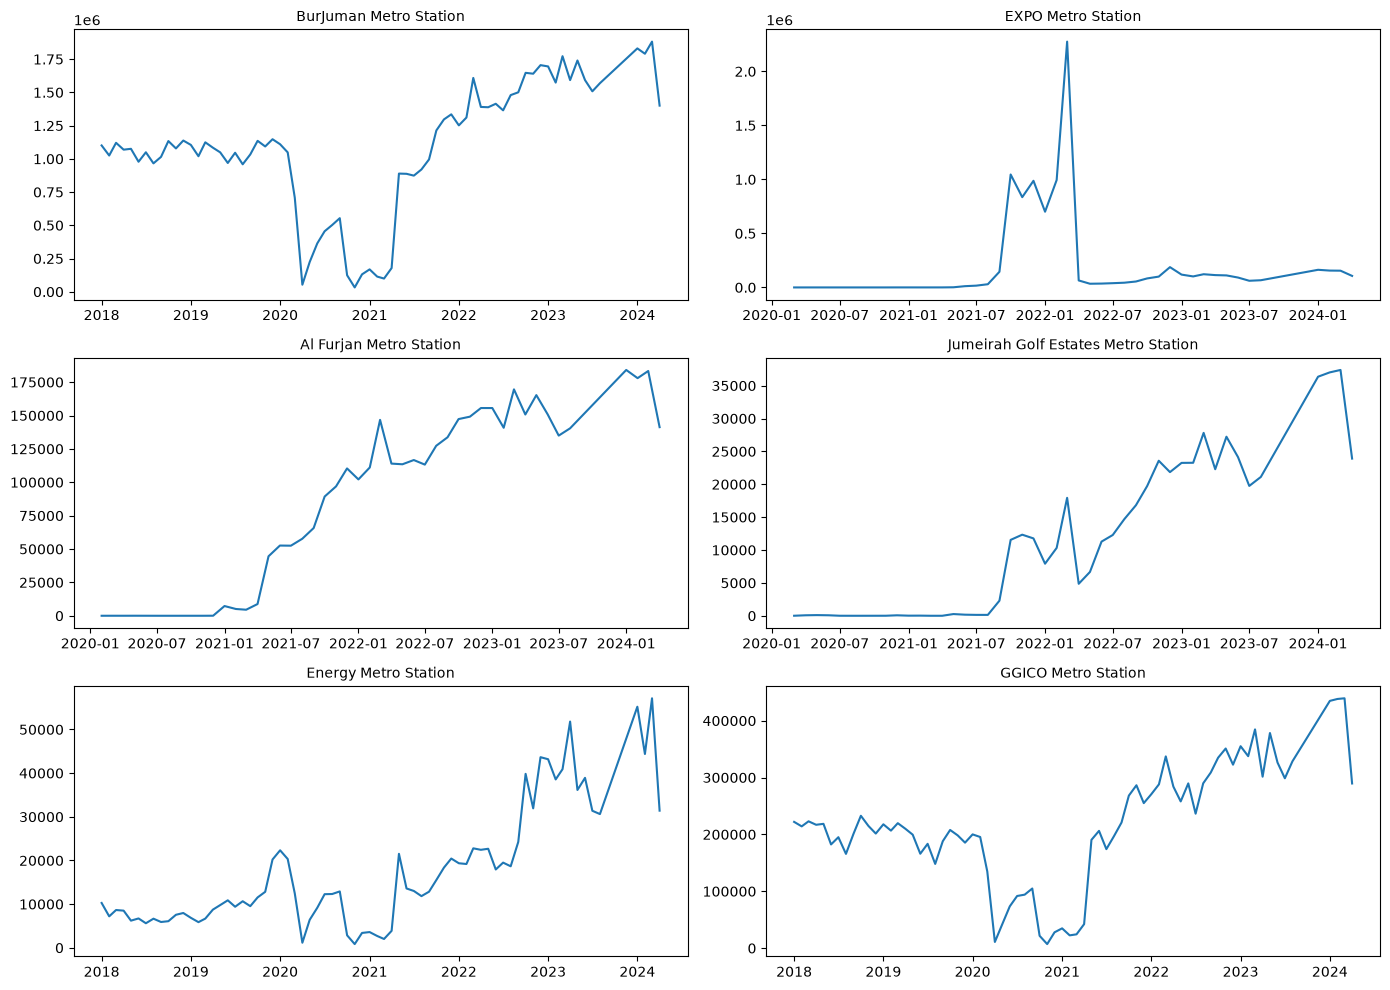

In [28]:
sample_stations = [
    'BurJuman Metro Station',           # highest volume, interchange
    'EXPO Metro Station',               # special-event outlier
    'Al Furjan Metro Station',          # Route 2020, moderate volatility
    'Jumeirah Golf Estates Metro Station',  # Route 2020, lowest volume
    'Energy Metro Station',             # small, high volatility
    'GGICO Metro Station',              # small, stable (renamed station, worth double-checking after our fixes)
]

fig, axes = plt.subplots(3, 2, figsize=(14, 10))
for ax, station in zip(axes.flat, sample_stations):
    sub = df_model[df_model['metro_station'] == station]
    ax.plot(sub['date'], sub['trips'])
    ax.set_title(station, fontsize=10)
plt.tight_layout()
plt.savefig("../docs/eda_08_diverse_sample.png", dpi=150, bbox_inches='tight')
plt.show()

In [3]:
import pandas as pd

df = pd.read_csv("../data_processed/metro_trips_model_ready.csv")

data_dict = []
for col in df.columns:
    data_dict.append({
        "Column": col,
        "Data Type": str(df[col].dtype),
        "Example Value": df[col].dropna().iloc[0],
        "Null Count": df[col].isna().sum(),
        "Unique Values": df[col].nunique()
    })

dict_df = pd.DataFrame(data_dict)
print(dict_df.to_string(index=False))

dict_df.to_csv("../docs/data_dictionary.csv", index=False)

        Column Data Type            Example Value  Null Count  Unique Values
 metro_station       str       ADCB Metro Station           0             53
         month       str                      Jan           0             12
         trips     int64                   576653           0           3373
          year     int64                     2018           0              6
load_timestamp       str 2018-03-07T15:45:02.000Z           0             68
     month_num     int64                        1           0             12
          date       str               2018-01-01           0             68
          line       str                      Red           0              4
      latitude   float64                 25.24451           0             53
     longitude   float64                55.298183           0             53
    month_name       str                      Jan           0             12
